# Creating a summary of the Hallmark and KEGG pathway gene sets across the DC2 cells in Ovarian Cancer
 DC2 reannotated clusters
* Using NR code from 2024-11-26_Pathway-Enrichment.ipynb
* using pathway gene sets downloaded in the local R Studio (I:\Group_Data\MR_Groups\RG05. Cancer Immunotherapies\01 Team Research Data\Luzia\R\NR_AtlasAnalysis, Pathway Enrichment.rmd)
* Using clustered cDC2 data - this one only has all the different cancer types in the Atlas
* Following code from ChatGPT
* Looking at primary vs mets only - Flip to make sure up is red in primary
* Ovarian Cancer samples
* Subset Hallmark and KEGG pathway sets to those of interest (from KT meeting 10.9.26) 
* Looking at updated DC2 clustering by NR - 2026-09-11_DC2_Updated_annotations_v2.ipynb

In [1]:
#load packages 
import os
import tools

In [2]:
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns
import numpy as np

In [3]:
import scanpy as sc
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

In [4]:
#show current directory 
os.getcwd()
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwayEnrichment')
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwayEnrichment'

### Read in the DC2 dataset
20250629_DC2_bbknn_clustered2.h5ad which is the DC2 only version of atlas


In [11]:
# read in data
data = sc.read_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250629_DC2_bbknn_clustered2.h5ad')

In [12]:
# Filter for multiple specific values using .isin()
cancer_stage = ['primary tumour', 'metastatic tumour']
data_sub = data[data.obs['sample_type_major2'].isin(cancer_stage)].copy()

Ovarian Cancer Only

In [13]:
#Filter to only have Ovarian Cancer data
data_oc = data_sub[data_sub.obs["cancer_with_H"] == "HGSOC"]
data_oc

View of AnnData object with n_obs × n_vars = 3044 × 2001
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'Guimaraes_DC2_FCER1A', 'Guimaraes_DC2_AREG', 'Guimaraes_Cheng_DC2_CD207/CD1A', 'Guimaraes_DC3_CD14', 'Guimaraes_DC4_FCGR3A', 'Guimaraes_DC_CXCL2', 'Cheng_DC2_CXCR4', 'Cheng_DC2_IL1B', 'Cheng_DC2_FCN1', 'Cheng_DC2_ISG15', 'Cheng_DC2_C

In [14]:
unique_count = data_oc.obs['sample_type_major2'].unique()
unique_count

['primary tumour', 'metastatic tumour']
Categories (2, object): ['metastatic tumour', 'primary tumour']

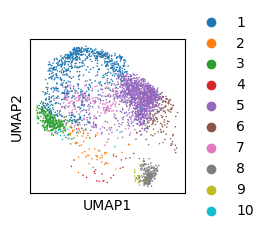

In [16]:
with plt.rc_context({"figure.figsize": (2, 2)}):
    sc.pl.umap(data_oc, color="cDC2_Atlas_Subclusters", size=5, title="")

Remove cluster 2 and 10 from DC2 OC object

In [17]:
data_oc = data_oc[~data_oc.obs["cDC2_Atlas_Subclusters"].isin(["2","10"])]

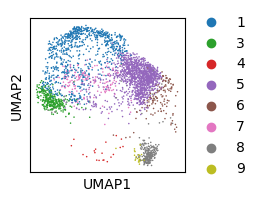

In [18]:
with plt.rc_context({"figure.figsize": (2, 2)}):
    sc.pl.umap(data_oc, color="cDC2_Atlas_Subclusters", size=5, title="")

Add DC2 subcluster annotations

In [19]:
data_oc

View of AnnData object with n_obs × n_vars = 2947 × 2001
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'Guimaraes_DC2_FCER1A', 'Guimaraes_DC2_AREG', 'Guimaraes_Cheng_DC2_CD207/CD1A', 'Guimaraes_DC3_CD14', 'Guimaraes_DC4_FCGR3A', 'Guimaraes_DC_CXCL2', 'Cheng_DC2_CXCR4', 'Cheng_DC2_IL1B', 'Cheng_DC2_FCN1', 'Cheng_DC2_ISG15', 'Cheng_DC2_C

In [20]:
# Assign DC2 annotations (from NR):
data_oc.obs["cDC2_sub_annotated"] = data_oc.obs["cDC2_Atlas_Subclusters"].map(
    {
        "1": "DC3-like cDC2",
        "3": "SIK3 cDC2",
        "4": "CD207-S100 cDC2",
        "5": "classical cDC2",
        "6": "ISG cDC2",
        "7": "classical cDC2",
        "8": "CD207-IL18 cDC2",
        "9": "CD207-LTB cDC2",
    }
)

/scratch/temp/28778441/ipykernel_204582/1155251323.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  data_oc.obs["cDC2_sub_annotated"] = data_oc.obs["cDC2_Atlas_Subclusters"].map(


In [22]:
print(data_oc.uns["cDC2_Atlas_Subclusters_colors"])

['#1f77b4' '#2ca02c' '#d62728' '#9467bd' '#8c564b' '#e377c2' '#7f7f7f'
 '#bcbd22']


In [77]:
# Set colours for cDC2_sub_annotated plot: - new
data_oc.uns["cDC2_sub_annotated_colors"] = ['#7f7f7f','#bcbd22','#d62728','#1f77b4','#8c564b','#2ca02c','#c869c9']

/scratch/temp/28778441/ipykernel_204582/3097244841.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(data_oc, color="cDC2_sub_annotated", size=20, save="_DC2_annotated_v2.svg")


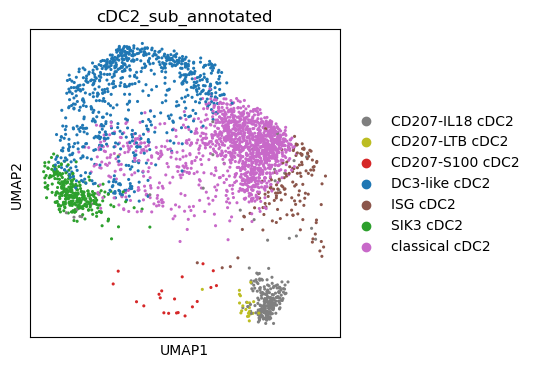

In [29]:
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(data_oc, color="cDC2_sub_annotated", size=20, save="_DC2_annotated_v2.svg")

In [31]:
print(data_oc.obs["cDC2_sub_annotated"])

PRJCA005422_EOC1_OC_cell_AAAGATGCAGACGTAG                                  DC3-like cDC2
PRJCA005422_EOC1_OC_cell_AACTCAGCAGCTCGAC                                 classical cDC2
PRJCA005422_EOC1_OC_cell_AAGACCTTCTGCTGCT                                  DC3-like cDC2
PRJCA005422_EOC1_OC_cell_ACAGCTACATGAAGTA                                 classical cDC2
PRJCA005422_EOC1_OC_cell_ACTGAGTCACAGTCGC                                  DC3-like cDC2
                                                                              ...       
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGATCAGCAGTGTGCC    CD207-IL18 cDC2
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGCGGCACAGAGGAAA     classical cDC2
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGGAGAGAGGCTTCCG     classical cDC2
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGTTGAGCAGCAAGAC     classical cDC2
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TTCTTCCTCGCCACTT      DC3-like cDC2
Name: cDC2_sub_annota

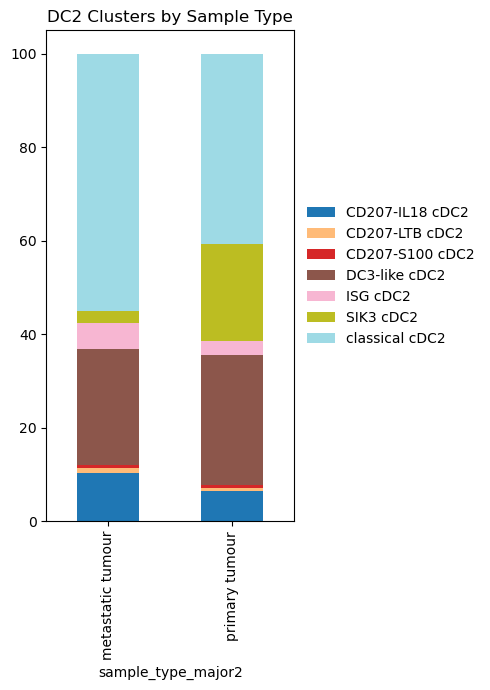

In [32]:
pd.crosstab(data_oc.obs["sample_type_major2"], data_oc.obs["cDC2_sub_annotated"]).apply(
    lambda r: r / r.sum() * 100, axis=1
).plot.bar(stacked=True, figsize=(5,7), colormap="tab20")
plt.legend(bbox_to_anchor=(1, 0.5), loc="center left", frameon=False)
plt.title("DC2 Clusters by Sample Type")
plt.tight_layout()  
plt.savefig("barplot_DC2_new_clusters_sample_type.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [80]:
# set colours for bar graph
colours10 = data_oc.uns["cDC2_sub_annotated_colors"]
clusters = data_oc.obs["cDC2_sub_annotated"].cat.categories
colour_dict = dict(zip(clusters, colours10))

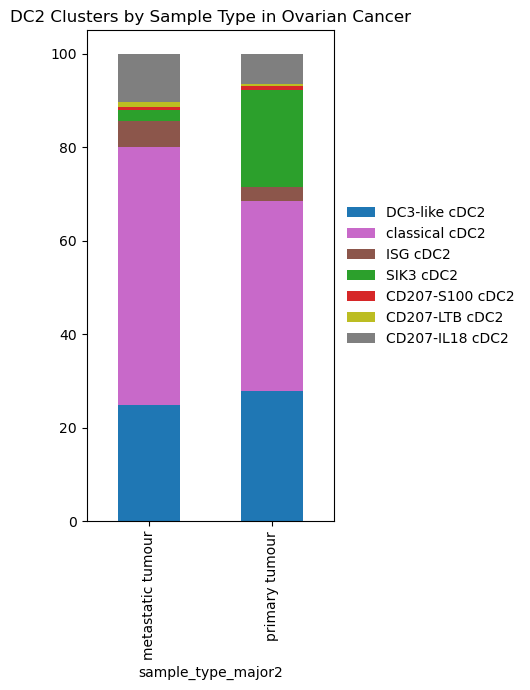

In [83]:
#plot stacked graph by sample type
ct = pd.crosstab(data_oc.obs["sample_type_major2"], data_oc.obs["cDC2_sub_annotated"])
ct_pct = ct.apply(lambda r: r / r.sum() * 100, axis=1)

# set order for stack
#ct_pct = ct_pct[["CD207-IL18 cDC2", "CD207-LTB cDC2", "CD207-S100 cDC2", "DC3-like cDC2","ISG cDC2","SIK3 cDC2","classical cDC2"]]

ct_pct = ct_pct[["DC3-like cDC2","classical cDC2", "ISG cDC2", "SIK3 cDC2", "CD207-S100 cDC2", "CD207-LTB cDC2", "CD207-IL18 cDC2" ]]

colours = [colour_dict[col] for col in ct_pct.columns]
ct_pct.plot.bar(stacked=True, figsize=(5,7), color=colours)
plt.legend(bbox_to_anchor=(1, 0.5), loc="center left", frameon=False)
plt.title("DC2 Clusters by Sample Type in Ovarian Cancer")
plt.tight_layout()  
plt.savefig("barplot_DC2_annotated_v2_sample_type.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [74]:
# Count cells per cell type per state
cell_counts = pd.crosstab(
   data_oc.obs["cDC2_sub_annotated"],
   data_oc.obs["sample_type_major2"])

print(cell_counts)

sample_type_major2  metastatic tumour  primary tumour
cDC2_sub_annotated                                   
CD207-IL18 cDC2                   173              82
CD207-LTB cDC2                     18               7
CD207-S100 cDC2                    10              10
DC3-like cDC2                     416             354
ISG cDC2                           94              38
SIK3 cDC2                          40             265
classical cDC2                    923             517


### Separate data into the different oc subsets to be analysed

In [40]:
data_CD207_IL18 = data_oc[data_oc.obs["cDC2_sub_annotated"] == "CD207-IL18 cDC2"]
data_CD207_LTB = data_oc[data_oc.obs["cDC2_sub_annotated"] == "CD207-LTB cDC2"]
data_CD207_S100 = data_oc[data_oc.obs["cDC2_sub_annotated"] == "CD207-S100 cDC2"]
data_ISG = data_oc[data_oc.obs["cDC2_sub_annotated"] == "ISG cDC2"]
data_SIK3 = data_oc[data_oc.obs["cDC2_sub_annotated"] == "SIK3 cDC2"]
data_dc2 = data_oc[data_oc.obs["cDC2_sub_annotated"] == "classical cDC2"]
data_dc3 = data_oc[data_oc.obs["cDC2_sub_annotated"] == "DC3-like cells"]

In [41]:
cell_type_data = {
    "CD207-IL18 cDC2": data_CD207_IL18,
    "CD207-LTB cDC2": data_CD207_LTB,
    "CD207-S100 cDC2": data_CD207_S100,
    "ISG cDC2":data_ISG,
    "SIK3 cDC2": data_SIK3,
    "classical cDC2": data_dc2,
    "DC3-like cells":data_dc3
}

### Import Hallmark gene pathways

Hallmark gene sets used here: (species = "Homo sapiens", collection = "C5", subcollection = "GO:BP")

In [84]:
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwaySets')
H_sets = pd.read_excel("hallmark_sets.xlsx", sheet_name=None)

In [85]:
# Change keys to be gene set name (the first value in the 'gs_name' column) instead of Sheet1 etc 
H_sets2 = {df["gs_name"].iloc[0]: df for _, df in H_sets.items()}
H_sets = H_sets2

# Result
print(H_sets.keys())

dict_keys(['HALLMARK_ADIPOGENESIS', 'HALLMARK_ALLOGRAFT_REJECTION', 'HALLMARK_ANDROGEN_RESPONSE', 'HALLMARK_ANGIOGENESIS', 'HALLMARK_APICAL_JUNCTION', 'HALLMARK_APICAL_SURFACE', 'HALLMARK_APOPTOSIS', 'HALLMARK_BILE_ACID_METABOLISM', 'HALLMARK_CHOLESTEROL_HOMEOSTASIS', 'HALLMARK_COAGULATION', 'HALLMARK_COMPLEMENT', 'HALLMARK_DNA_REPAIR', 'HALLMARK_E2F_TARGETS', 'HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION', 'HALLMARK_ESTROGEN_RESPONSE_EARLY', 'HALLMARK_ESTROGEN_RESPONSE_LATE', 'HALLMARK_FATTY_ACID_METABOLISM', 'HALLMARK_G2M_CHECKPOINT', 'HALLMARK_GLYCOLYSIS', 'HALLMARK_HEDGEHOG_SIGNALING', 'HALLMARK_HEME_METABOLISM', 'HALLMARK_HYPOXIA', 'HALLMARK_IL2_STAT5_SIGNALING', 'HALLMARK_IL6_JAK_STAT3_SIGNALING', 'HALLMARK_INFLAMMATORY_RESPONSE', 'HALLMARK_INTERFERON_ALPHA_RESPONSE', 'HALLMARK_INTERFERON_GAMMA_RESPONSE', 'HALLMARK_KRAS_SIGNALING_DN', 'HALLMARK_KRAS_SIGNALING_UP', 'HALLMARK_MITOTIC_SPINDLE', 'HALLMARK_MTORC1_SIGNALING', 'HALLMARK_MYC_TARGETS_V1', 'HALLMARK_MYC_TARGETS_V2', 'HALLMAR

Subset to only include pathways of interest

In [86]:
keys_include = [
"HALLMARK_COMPLEMENT",
"HALLMARK_GLYCOLYSIS",
"HALLMARK_HYPOXIA",
"HALLMARK_IL2_STAT5_SIGNALING",
"HALLMARK_IL6_JAK_STAT3_SIGNALING",
"HALLMARK_INFLAMMATORY_RESPONSE",
"HALLMARK_INTERFERON_ALPHA_RESPONSE",
"HALLMARK_INTERFERON_GAMMA_RESPONSE",
"HALLMARK_OXIDATIVE_PHOSPHORYLATION",
"HALLMARK_TGF_BETA_SIGNALING",
"HALLMARK_TNFA_SIGNALING_VIA_NFKB",
]

In [87]:
# create a new dictionary with select keys (pathway sets)
H_sets_sub = {key: H_sets[key] for key in keys_include if key in H_sets}

# Display the new dictionary
H_sets_sub

{'HALLMARK_COMPLEMENT':     gene_symbol  ncbi_gene     ensembl_gene db_gene_symbol  db_ncbi_gene  \
 0         ACTN2         88  ENSG00000077522          ACTN2            88   
 1         ADAM9       8754  ENSG00000168615          ADAM9          8754   
 2        ADRA2B        151  ENSG00000274286         ADRA2B           151   
 3        AKAP10      11216  ENSG00000108599         AKAP10         11216   
 4           ANG        283  ENSG00000214274            ANG           283   
 ..          ...        ...              ...            ...           ...   
 195      VCPIP1      80124  ENSG00000175073         VCPIP1         80124   
 196         WAS       7454  ENSG00000015285            WAS          7454   
 197     XPNPEP1       7511  ENSG00000108039        XPNPEP1          7511   
 198        ZEB1       6935  ENSG00000148516           ZEB1          6935   
 199       ZFPM2      23414  ENSG00000169946          ZFPM2         23414   
 
      db_ensembl_gene source_gene  gs_id           

Score each DC subset according to the Hallmark gene sets

In [88]:
# Iterate through each gene set in H_sets_sub - CD207-IL18
for set_name, gene_set_df in H_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_CD207_IL18, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets_sub - CD207-LTB
for set_name, gene_set_df in H_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_CD207_LTB, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets_sub - CD207-S100
for set_name, gene_set_df in H_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_CD207_S100, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets_sub - data_ISG
for set_name, gene_set_df in H_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_ISG, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in H_sets_sub - data SIK3 like cells
for set_name, gene_set_df in H_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_SIK3, gene_list=gene_set, score_name=f"{set_name}_score")

    
    # Iterate through each gene set in H_sets_sub - DC2 cells
for set_name, gene_set_df in H_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_dc2, gene_list=gene_set, score_name=f"{set_name}_score")

       'MMP12', 'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'GFUS', 'GPR87', 'GYS2', 'LCT', 'LHX9', 'NOL3', 'PFKFB1', 'PGLS',
       'RARS1'],
      dtype='object')
       'GAPDHS', 'GCK', 'HOXB9', 'IGFBP1', 'INHA', 'KIF5A', 'LALBA', 'LARGE1',
       'NCAN', 'NOCT', 'PCK1', 'PKLR', 'PPARGC1A', 'PPP1R3C', 'STBD1'],
      dtype='object')
       'PLPP1', 'PTH1R'],
      dtype='object')
       'NPFFR2', 'OPRK1', 'ROS1', 'SELENOS', 'SLC28A2', 'TACR3', 'VIP'],
      dtype='object')
       'ATP5MC2', 'ATP5MC3', 'ATP5ME', 'ATP5MF', 'ATP5MG', 'ATP5PB', 'ATP5PD',
       'ATP5PF', 'ATP5PO', 'TOMM70'],
      dtype='object')
       'MMP12', 'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')
       'GFUS', 'GPR87', 'GYS2', 'LCT', 'LHX9', 'NOL3', 'PFKFB1', 'PGLS',
       'RARS1'],
      dtype='object')
       'GAPDHS', 'GCK', 'HOXB9', 'IGFBP1', 'INHA', 'KIF5A', 'LALBA', 'LARGE1',
       'NCAN', 'NOCT', 'PCK1', 'PKLR', 'PPARGC1A', 'PPP1R3C', 'STBD1'],
      dtype='object')
      

In [71]:
    # Iterate through each gene set in H_sets_sub - DC3 like cells
for set_name, gene_set_df in H_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_dc3, gene_list=gene_set, score_name=f"{set_name}_score")

       'MMP12', 'MMP8', 'PCSK9', 'PLG', 'RBSN'],
      dtype='object')


/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:47: RuntimeWarning: invalid value encountered in divide
  m = s / n_elements


KeyError: "None of [Index(['ACTN2', 'ADAM9', 'ADRA2B', 'AKAP10', 'ANG', 'ANXA5', 'APOBEC3F',\n       'APOBEC3G', 'APOC1', 'ATOX1',\n       ...\n       'TNFAIP3', 'USP14', 'USP15', 'USP16', 'USP8', 'VCPIP1', 'WAS',\n       'XPNPEP1', 'ZEB1', 'ZFPM2'],\n      dtype='object', length=186)] are in the [index]"

No common genes in the Hallmark gene set and the DC3 gene list

### Import KEGG gene pathways

KEGG gene sets used here: (species = "human", collection = "C2", subcollection = "CP:KEGG_LEGACY")

In [49]:
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/PathwaySets')
K_sets = pd.read_excel("kegg_sets.xlsx", sheet_name=None)

In [50]:
# Change keys to be gene set name (the first value in the 'gs_name' column) instead of Sheet1 etc 
K_sets2 = {df["gs_name"].iloc[0]: df for _, df in K_sets.items()}
K_sets = K_sets2

# Result
print(K_sets.keys())

dict_keys(['KEGG_ABC_TRANSPORTERS', 'KEGG_ACUTE_MYELOID_LEUKEMIA', 'KEGG_ADHERENS_JUNCTION', 'KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY', 'KEGG_ALANINE_ASPARTATE_AND_GLUTAMATE_METABOLISM', 'KEGG_ALDOSTERONE_REGULATED_SODIUM_REABSORPTION', 'KEGG_ALLOGRAFT_REJECTION', 'KEGG_ALPHA_LINOLENIC_ACID_METABOLISM', 'KEGG_ALZHEIMERS_DISEASE', 'KEGG_AMINO_SUGAR_AND_NUCLEOTIDE_SUGAR_METABOLISM', 'KEGG_AMINOACYL_TRNA_BIOSYNTHESIS', 'KEGG_AMYOTROPHIC_LATERAL_SCLEROSIS_ALS', 'KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION', 'KEGG_APOPTOSIS', 'KEGG_ARACHIDONIC_ACID_METABOLISM', 'KEGG_ARGININE_AND_PROLINE_METABOLISM', 'KEGG_ARRHYTHMOGENIC_RIGHT_VENTRICULAR_CARDIOMYOPATHY_ARVC', 'KEGG_ASCORBATE_AND_ALDARATE_METABOLISM', 'KEGG_ASTHMA', 'KEGG_AUTOIMMUNE_THYROID_DISEASE', 'KEGG_AXON_GUIDANCE', 'KEGG_B_CELL_RECEPTOR_SIGNALING_PATHWAY', 'KEGG_BASAL_CELL_CARCINOMA', 'KEGG_BASAL_TRANSCRIPTION_FACTORS', 'KEGG_BASE_EXCISION_REPAIR', 'KEGG_BETA_ALANINE_METABOLISM', 'KEGG_BIOSYNTHESIS_OF_UNSATURATED_FATTY_ACIDS', 'KEGG_BLADDE

Remove unnecessary KEGG sets

In [89]:
# Keys to include in new dictionary
keys_include = [
"KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION",
"KEGG_CHEMOKINE_SIGNALING_PATHWAY",
"KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION",
]

In [54]:
# create a new dictionary with select keys (pathway sets)
K_sets_sub = {key: K_sets[key] for key in keys_include if key in K_sets}

# Display the new dictionary
K_sets_sub

{'KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION':     gene_symbol  ncbi_gene     ensembl_gene db_gene_symbol  db_ncbi_gene  \
 0           B2M        567  ENSG00000166710            B2M           567   
 1          CALR        811  ENSG00000179218           CALR           811   
 2          CANX        821  ENSG00000127022           CANX           821   
 3           CD4        920  ENSG00000010610            CD4           920   
 4          CD74        972  ENSG00000019582           CD74           972   
 ..          ...        ...              ...            ...           ...   
 108      RFXANK       8625  ENSG00000064490         RFXANK          8625   
 109       RFXAP       5994  ENSG00000133111          RFXAP          5994   
 110        TAP1       6890  ENSG00000168394           TAP1          6890   
 111        TAP2       6891  ENSG00000204267           TAP2          6891   
 112       TAPBP       6892  ENSG00000231925          TAPBP          6892   
 
      db_ensembl_gene  source_

Score each DC subset according to the KEGG pathway sets

In [90]:
# Iterate through each gene set in K_sets_sub - CD207-IL18
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_CD207_IL18, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in K_sets_sub - CD207-LTB
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_CD207_LTB, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in K_sets_sub - CD207-S100
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_CD207_S100, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in K_sets_sub - data_ISG
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_ISG, gene_list=gene_set, score_name=f"{set_name}_score")

# Iterate through each gene set in K_sets_sub - data SIK3 like cells
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_SIK3, gene_list=gene_set, score_name=f"{set_name}_score")

    # Iterate through each gene set in K_sets_sub - DC3 like cells
#for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    #gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    #sc.tl.score_genes(data_dc3, gene_list=gene_set, score_name=f"{set_name}_score")

    
    # Iterate through each gene set in K_sets_sub - DC2 cells
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_dc2, gene_list=gene_set, score_name=f"{set_name}_score")

       'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7',
       'IFNA8', 'KIR2DL1', 'KIR2DL2', 'KIR2DL3', 'KIR2DL4', 'KIR2DL5A',
       'KIR2DS1', 'KIR2DS3', 'KIR2DS4', 'KIR2DS5', 'KIR3DL3', 'KLRC3'],
      dtype='object')
       'CCL27', 'CCL3L3', 'CCR8', 'CXCL8', 'GNB3', 'GNG13', 'GNG3', 'GNGT1',
       'GRK1', 'GRK2', 'GRK3', 'PF4', 'PF4V1', 'PPBPP1', 'PRKACG', 'SHC2'],
      dtype='object')
       'CCR8', 'CNTFR', 'CXCL8', 'EDAR', 'EGF', 'EPO', 'FLT4', 'GDF5', 'GH1',
       'GH2', 'IFNA1', 'IFNA10', 'IFNA13', 'IFNA14', 'IFNA16', 'IFNA17',
       'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7', 'IFNA8', 'IFNE',
       'IFNK', 'IFNL2', 'IFNL3', 'IFNW1', 'IL12A', 'IL13', 'IL17A', 'IL17B',
       'IL2', 'IL21', 'IL22', 'IL22RA1', 'IL25', 'IL26', 'IL3', 'IL4', 'IL5',
       'IL9', 'INHBC', 'INHBE', 'LEP', 'MPL', 'PF4', 'PF4V1', 'PPBPP1', 'PRL',
       'TGFB1', 'TNFRSF6B', 'TPO', 'TSLP', 'VEGFC', 'VEGFD'],
      dtype='object')
       'IFNA17', 'IFNA2', 'IFNA21', 'IF

In [73]:
    # Iterate through each gene set in K_sets_sub - DC3 cells
for set_name, gene_set_df in K_sets_sub.items():
    # Extract the gene set from the 'gene_symbol' column of the dataframe
    gene_set = gene_set_df['gene_symbol'].tolist()
    
    # Score the cells using the gene set
    sc.tl.score_genes(data_dc3, gene_list=gene_set, score_name=f"{set_name}_score")

       'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7',
       'IFNA8', 'KIR2DL1', 'KIR2DL2', 'KIR2DL3', 'KIR2DL4', 'KIR2DL5A',
       'KIR2DS1', 'KIR2DS3', 'KIR2DS4', 'KIR2DS5', 'KIR3DL3', 'KLRC3'],
      dtype='object')


/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:47: RuntimeWarning: invalid value encountered in divide
  m = s / n_elements


KeyError: "None of [Index(['B2M', 'CALR', 'CANX', 'CD4', 'CD74', 'CD8A', 'CD8B', 'CIITA', 'CREB1',\n       'CTSB', 'CTSL', 'CTSS', 'HLA-A', 'HLA-B', 'HLA-C', 'HLA-DMA', 'HLA-DMB',\n       'HLA-DOA', 'HLA-DOB', 'HLA-DPA1', 'HLA-DPB1', 'HLA-DQA1', 'HLA-DQA2',\n       'HLA-DQB1', 'HLA-DRA', 'HLA-DRB1', 'HLA-DRB5', 'HLA-E', 'HLA-F',\n       'HLA-G', 'HSP90AA1', 'HSP90AB1', 'HSPA1A', 'HSPA1B', 'HSPA1L', 'HSPA2',\n       'HSPA4', 'HSPA5', 'HSPA6', 'HSPA8', 'IFI30', 'KIR3DL1', 'KIR3DL2',\n       'KLRC1', 'KLRC2', 'KLRC4', 'KLRD1', 'LGMN', 'LTA', 'NFYA', 'NFYB',\n       'NFYC', 'PDIA3', 'PSME1', 'PSME2', 'PSME3', 'RFX5', 'RFXANK', 'RFXAP',\n       'TAP1', 'TAP2', 'TAPBP'],\n      dtype='object')] are in the [index]"

No common genes in the Hallmark gene set and the DC3 gene list

## First, calculate the pathway differences for all 5 cell types

# Run KEGG pathway first

In [91]:
results = []

for cell_type, adata in cell_type_data.items():

    obs_df = adata.obs.copy()

    # Keep only primary and metastatic
    obs_df = obs_df[
        obs_df["sample_type_major2"].isin(
            ["metastatic tumour", "primary tumour"]
        )
    ]

    for gene_set in K_sets_sub.keys():

        score_col = f"{gene_set}_score"

        if score_col not in obs_df.columns:
            continue

        # Remove missing values
        data = obs_df[
            ["sample_type_major2", score_col]
        ].dropna()

        metastatic = data.loc[
            data["sample_type_major2"] == "metastatic tumour",
            score_col
        ]

        primary = data.loc[
            data["sample_type_major2"] == "primary tumour",
            score_col
        ]


        if len(metastatic) == 0 or len(primary) == 0:
            continue

        # Welch t-test
        stat, p_value = ttest_ind(
            metastatic,
            primary,
            equal_var=False
        )
        
        mean_metastatic = metastatic.mean()
        mean_primary = primary.mean()
        
        results.append({
            "Cell Type": cell_type,
            "Gene Set": gene_set,
            "Metastatic Mean": mean_metastatic,
            "Primary Mean": mean_primary,
            "Difference": mean_primary - mean_metastatic,
            "P-value": p_value
        })

results_df = pd.DataFrame(results)

In [92]:
data_CD207_IL18.obs.columns.tolist()

['nCount_RNA',
 'nFeature_RNA',
 'sample_type',
 'cancer_type',
 'patient_id',
 'sample_id',
 'percent.mt',
 'site',
 'sample_type_major',
 'cancer_subtype',
 'integration_id',
 'ident',
 'dataset_id',
 'n_genes_by_counts',
 'log1p_n_genes_by_counts',
 'total_counts',
 'log1p_total_counts',
 'pct_counts_in_top_50_genes',
 'pct_counts_in_top_100_genes',
 'pct_counts_in_top_200_genes',
 'pct_counts_in_top_500_genes',
 'total_counts_mt',
 'log1p_total_counts_mt',
 'pct_counts_mt',
 'S_score',
 'G2M_score',
 'keep_or_remove',
 'leiden',
 'celltype',
 'leiden_DC',
 'leiden_DC_v2',
 'exclude_annots',
 'leiden_M',
 'Technology',
 'NR_annotations_simple',
 'sample_type_major2',
 'cancer_with_H',
 'cancer_broadest',
 'patient_treatment',
 'Guimaraes_DC2_FCER1A',
 'Guimaraes_DC2_AREG',
 'Guimaraes_Cheng_DC2_CD207/CD1A',
 'Guimaraes_DC3_CD14',
 'Guimaraes_DC4_FCGR3A',
 'Guimaraes_DC_CXCL2',
 'Cheng_DC2_CXCR4',
 'Cheng_DC2_IL1B',
 'Cheng_DC2_FCN1',
 'Cheng_DC2_ISG15',
 'Cheng_DC2_CXCL9',
 'DC3_sig

In [93]:
print(results_df.shape)
print(results_df.columns.tolist())
print(results_df.head())

(18, 6)
['Cell Type', 'Gene Set', 'Metastatic Mean', 'Primary Mean', 'Difference', 'P-value']
         Cell Type                                     Gene Set  \
0  CD207-IL18 cDC2     KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION   
1  CD207-IL18 cDC2             KEGG_CHEMOKINE_SIGNALING_PATHWAY   
2  CD207-IL18 cDC2  KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION   
3   CD207-LTB cDC2     KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION   
4   CD207-LTB cDC2             KEGG_CHEMOKINE_SIGNALING_PATHWAY   

   Metastatic Mean  Primary Mean  Difference   P-value  
0         1.006258      0.929751   -0.076507  0.000204  
1         0.052401      0.061764    0.009363  0.053888  
2        -0.092695     -0.093400   -0.000705  0.887701  
3         0.837752      0.830200   -0.007551  0.866955  
4        -0.006627     -0.005858    0.000769  0.942512  


Correct the p-values for multiple testing

In [94]:
results_df["FDR"] = multipletests(
    results_df["P-value"],
    method="fdr_bh"
)[1]

Create a significance label

In [95]:
def significance_label(fdr):
    if fdr < 0.0001:
        return "****"
    elif fdr < 0.001:
        return "***"
    elif fdr < 0.01:
        return "**"
    elif fdr < 0.05:
        return "*"
    else:
        return ""

results_df["Significance"] = results_df["FDR"].apply(
    significance_label
)

Make the summary heatmap

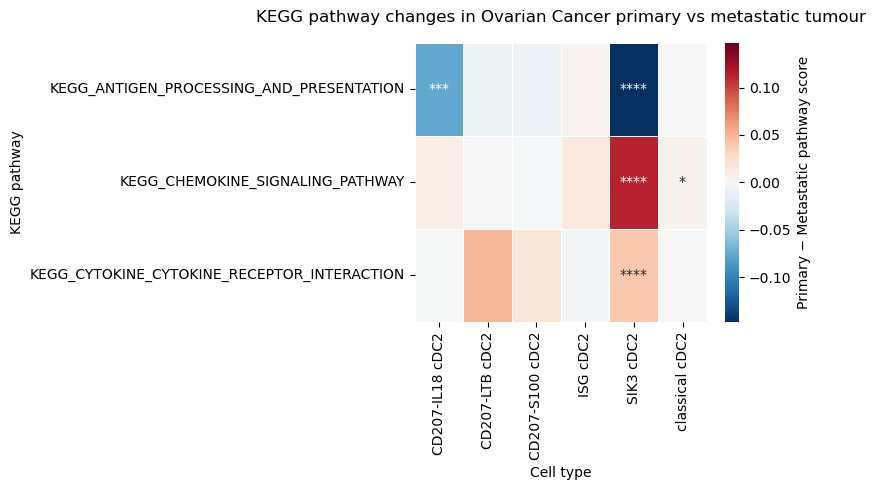

In [96]:
# Convert to matrix
heatmap_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Difference"
)

# Significance matrix
significance_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Significance"
)

# Create figure
plt.figure(
    figsize=(8, max(5, len(heatmap_data) * 0.35))
)

# Make colour scale symmetric around zero
max_abs = np.nanmax(np.abs(heatmap_data.values))

ax = sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    annot=significance_data,
    fmt="",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Primary − Metastatic pathway score"
    }
)

plt.xlabel("Cell type")
plt.ylabel("KEGG pathway")

plt.title(
    "KEGG pathway changes in Ovarian Cancer primary vs metastatic tumour",
    pad=15
)

plt.tight_layout()
plt.show()

In [97]:
# OPTIONAL: Order pathways by average effect across cell types
pathway_order = (
    heatmap_data
    .mean(axis=1)
    .sort_values()
    .index
)

heatmap_data = heatmap_data.loc[pathway_order]
significance_data = significance_data.loc[pathway_order]

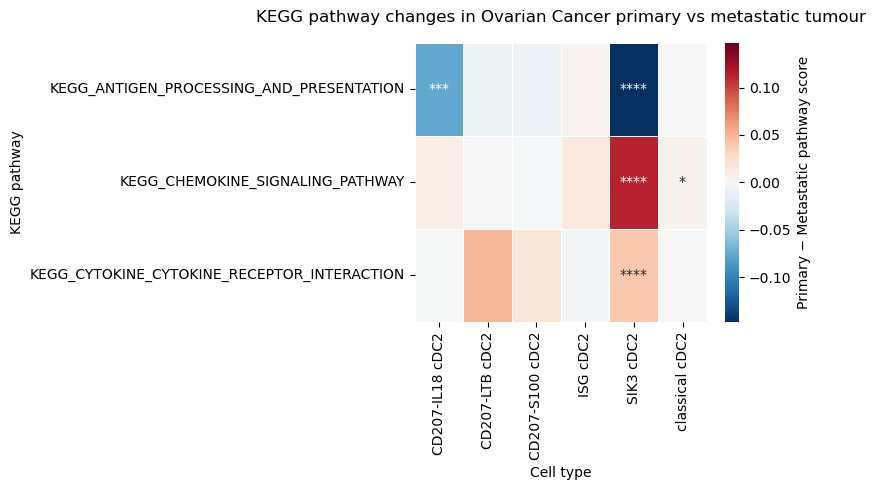

In [98]:
# Convert to matrix
heatmap_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Difference"
)

# Significance matrix
significance_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Significance"
)

# Create figure
plt.figure(
    figsize=(8,max(5 , len(heatmap_data) * 0.35))
)

# Make colour scale symmetric around zero
max_abs = np.nanmax(np.abs(heatmap_data.values))

ax = sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    annot=significance_data,
    fmt="",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Primary − Metastatic pathway score"
    }
)

plt.xlabel("Cell type")
plt.ylabel("KEGG pathway")

plt.title(
    "KEGG pathway changes in Ovarian Cancer primary vs metastatic tumour",
    pad=15
)

plt.tight_layout()
plt.show()

# Run Hallmark pathway

In [99]:
del results
del results_df

In [100]:
results = []

for cell_type, adata in cell_type_data.items():

    obs_df = adata.obs.copy()

    # Keep only primary and metastatic
    obs_df = obs_df[
        obs_df["sample_type_major2"].isin(
            ["metastatic tumour", "primary tumour"]
        )
    ]

    for gene_set in H_sets.keys():

        score_col = f"{gene_set}_score"

        if score_col not in obs_df.columns:
            continue

        # Remove missing values
        data = obs_df[
            ["sample_type_major2", score_col]
        ].dropna()

        metastatic = data.loc[
            data["sample_type_major2"] == "metastatic tumour",
            score_col
        ]

        primary = data.loc[
            data["sample_type_major2"] == "primary tumour",
            score_col
        ]

        if len(metastatic) == 0 or len(primary) == 0:
            continue

        # Welch t-test
        stat, p_value = ttest_ind(
            metastatic,
            primary,
            equal_var=False
        )

        mean_metastatic = metastatic.mean()
        mean_primary = primary.mean()
        

        results.append({
            "Cell Type": cell_type,
            "Gene Set": gene_set,
            "Metastatic Mean": mean_metastatic,
            "Primary Mean": mean_primary,
            "Difference": mean_primary - mean_metastatic,
            "P-value": p_value
        })

results_df = pd.DataFrame(results)

In [101]:
print(results_df.shape)
print(results_df.columns.tolist())
print(results_df.head())

(66, 6)
['Cell Type', 'Gene Set', 'Metastatic Mean', 'Primary Mean', 'Difference', 'P-value']
         Cell Type                          Gene Set  Metastatic Mean  \
0  CD207-IL18 cDC2               HALLMARK_COMPLEMENT         0.102579   
1  CD207-IL18 cDC2               HALLMARK_GLYCOLYSIS         0.005752   
2  CD207-IL18 cDC2                  HALLMARK_HYPOXIA         0.108660   
3  CD207-IL18 cDC2      HALLMARK_IL2_STAT5_SIGNALING         0.044222   
4  CD207-IL18 cDC2  HALLMARK_IL6_JAK_STAT3_SIGNALING         0.032795   

   Primary Mean  Difference   P-value  
0      0.097785   -0.004794  0.361408  
1      0.004430   -0.001322  0.776011  
2      0.104013   -0.004647  0.473290  
3      0.044535    0.000313  0.957428  
4      0.043912    0.011118  0.192234  


Correct the p values for multiple testing

In [102]:
results_df["FDR"] = multipletests(
    results_df["P-value"],
    method="fdr_bh"
)[1]

In [103]:
def significance_label(fdr):
    if fdr < 0.0001:
        return "****"
    elif fdr < 0.001:
        return "***"
    elif fdr < 0.01:
        return "**"
    elif fdr < 0.05:
        return "*"
    else:
        return ""

results_df["Significance"] = results_df["FDR"].apply(
    significance_label
)

Make a summary heatmap

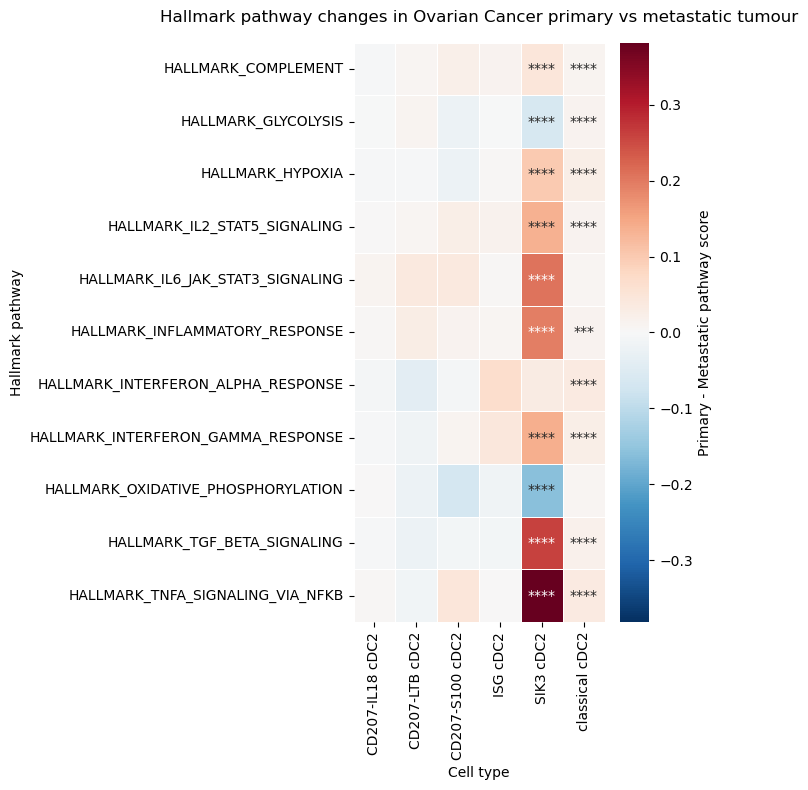

In [104]:
# Convert to matrix
heatmap_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Difference"
)

# Significance matrix
significance_data = results_df.pivot(
    index="Gene Set",
    columns="Cell Type",
    values="Significance"
)

# Create figure
plt.figure(
    figsize=(
        7,
        max(8, len(heatmap_data) * 0.35)
    )
)

# Make colour scale symmetric around zero
max_abs = np.nanmax(np.abs(heatmap_data.values))

ax = sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    annot=significance_data,
    fmt="",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Primary - Metastatic pathway score"
    }
)

plt.xlabel("Cell type")
plt.ylabel("Hallmark pathway")

plt.title(
    "Hallmark pathway changes in Ovarian Cancer primary vs metastatic tumour",
    pad=15
)

plt.tight_layout()
plt.show()

### Subset Hallmark genes

In [ ]:
# Keys to include in new dictionary
keys_include = ["KEGG_ADIPOCYTOKINE_SIGNALING_PATHWAY",
"KEGG_ANTIGEN_PROCESSING_AND_PRESENTATION",
"KEGG_APOPTOSIS",
"KEGG_CALCIUM_SIGNALING_PATHWAY",
"KEGG_CELL_ADHESION_MOLECULES_CAMS",
"KEGG_CHEMOKINE_SIGNALING_PATHWAY",
"KEGG_CYTOKINE_CYTOKINE_RECEPTOR_INTERACTION",
"KEGG_CYTOSOLIC_DNA_SENSING_PATHWAY",
"KEGG_ENDOCYTOSIS",
"KEGG_FATTY_ACID_METABOLISM",
"KEGG_FC_GAMMA_R_MEDIATED_PHAGOCYTOSIS",
"KEGG_GLYCOLYSIS_GLUCONEOGENESIS",
"KEGG_JAK_STAT_SIGNALING_PATHWAY",
"KEGG_LEUKOCYTE_TRANSENDOTHELIAL_MIGRATION",
"KEGG_MAPK_SIGNALING_PATHWAY",
"KEGG_NOD_LIKE_RECEPTOR_SIGNALING_PATHWAY",
"KEGG_NOTCH_SIGNALING_PATHWAY",
"KEGG_OXIDATIVE_PHOSPHORYLATION",
"KEGG_PROTEASOME",
"KEGG_PROTEIN_EXPORT",
"KEGG_TGF_BETA_SIGNALING_PATHWAY",
"KEGG_TOLL_LIKE_RECEPTOR_SIGNALING_PATHWAY",
"KEGG_TYROSINE_METABOLISM",
"KEGG_UBIQUITIN_MEDIATED_PROTEOLYSIS",
"KEGG_VEGF_SIGNALING_PATHWAY"]